# Stage cut versus performance in gas membrane separators

**Stage cut** is the fraction of the feed that passes through the membrane:

$$\theta = \frac{\text{permeate flow}}{\text{feed flow}}$$

It is the main operating knob of a membrane stage. Raising θ always does three things at once:

* **recovery** of the fast gas in the permeate goes **up**,
* **purity** of the permeate goes **down** (more of the slow gas is dragged through),
* the **membrane area** needed goes **up**,

while the retentate becomes purer in the slow gas. How steep these trade-offs are depends on the
membrane selectivity α, the pressure ratio φ = p<sub>feed</sub>/p<sub>permeate</sub>, the feed
composition and the **flow pattern** inside the module.

| Notebook | Model | What it shows |
|---|---|---|
| 01 | Well-mixed (complete mixing) | Closed-form binary solution; the baseline |
| 02 | Cross-flow | Numerical model checked against the Weller–Steiner analytical solution |
| 03 | Co-current and counter-current | Plug flow on both sides; why counter-current wins; pinch behaviour |
| 04 | Multicomponent | Biogas, flue gas, hydrogen and air feeds |
| 05 | Fixed module + pressure drop | Stage cut as an *output*; bore-side pressure drop |
| 06 | Multistage, energy, cost | Recycle cascades; compressor and vacuum power; indicative cost |
| 07 | Validation | Comparison with Pan (1986), Merkel (2010), Coker (1998), Makaruk (2010) and Feng (1999) |
| 08 | Point by point | 274 digitised measurements from Pan and Feng, plus Makaruk's model curves |

Every notebook runs top to bottom. Interactive cells use `ipywidgets`; if the sliders do not
appear, run `pip install ipywidgets` and restart the kernel.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: zip unzipped in /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if TOOLKIT is None and IN_COLAB:
    print("Looking for the toolkit in your Google Drive (approve the access request)...")
    from google.colab import drive
    drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
    if TOOLKIT is None:
        print("Not found in Drive. Choose gas-membrane-stagecut-toolkit.zip to upload:")
        import zipfile
        from google.colab import files
        for name in files.upload():
            zipfile.ZipFile(name).extractall("/content")
        TOOLKIT = _find_toolkit()
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "the unzipped gas-membrane-stagecut-toolkit folder.")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


## A first look: one binary separation, four flow patterns

Fast gas A at 20 % in the feed, selectivity α = 10, pressure ratio φ = 4.

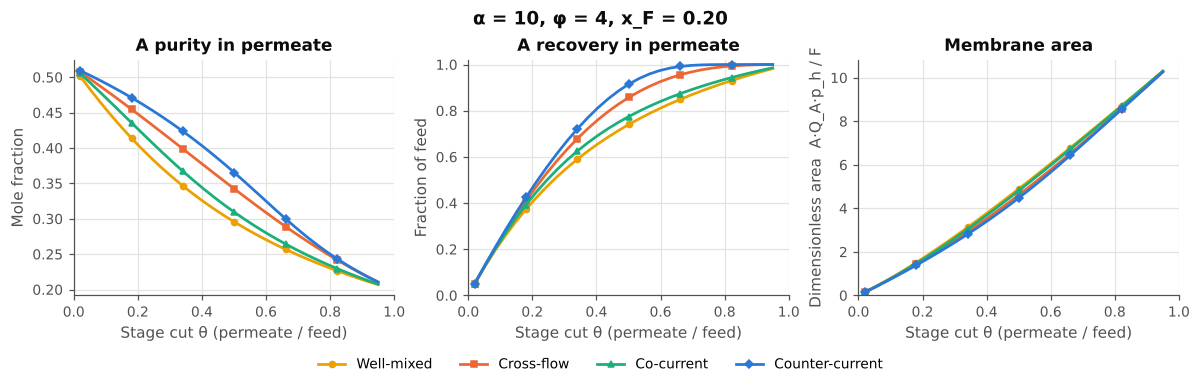

In [2]:
df = binary_sweep(alpha=10, phi=4, x_feed=0.2, thetas=np.linspace(0.02, 0.95, 30))
fig = plot_stage_cut_tradeoff(df, "A", area_col="area_dimless",
                              area_label="Dimensionless area  A·Q_A·p_h / F",
                              title="α = 10, φ = 4, x_F = 0.20")

Two numbers set an upper bound on permeate purity, whatever the stage cut:

* the **selectivity limit**, reached when the pressure ratio is infinite;
* the **pressure-ratio limit**, y ≤ φ·x, reached when the selectivity is infinite.

When φ is much smaller than α the separation is **pressure-ratio limited**: buying a more selective
membrane barely helps. Try it below.

In [3]:
def limits(alpha=10.0, phi=4.0, x=0.2):
    r = binary_limits(alpha, phi, x)
    display(Markdown(
        f"Selectivity limit **{r['y_selectivity_limit']:.3f}** · "
        f"pressure-ratio limit **{r['y_pressure_ratio_limit']:.3f}** · "
        f"actual (θ → 0) **{r['y_local']:.3f}** → *{r['regime']}* (φ/α = {r['phi_over_alpha']:.2f})"))

w.interact(limits,
           alpha=w.FloatLogSlider(value=10, base=10, min=0.1, max=3, step=0.05, description="α"),
           phi=w.FloatLogSlider(value=4, base=10, min=0.05, max=3, step=0.05, description="φ"),
           x=w.FloatSlider(value=0.2, min=0.01, max=0.9, step=0.01, description="x feed"));

interactive(children=(FloatLogSlider(value=10.0, description='α', max=3.0, min=0.1, step=0.05), FloatLogSlider…

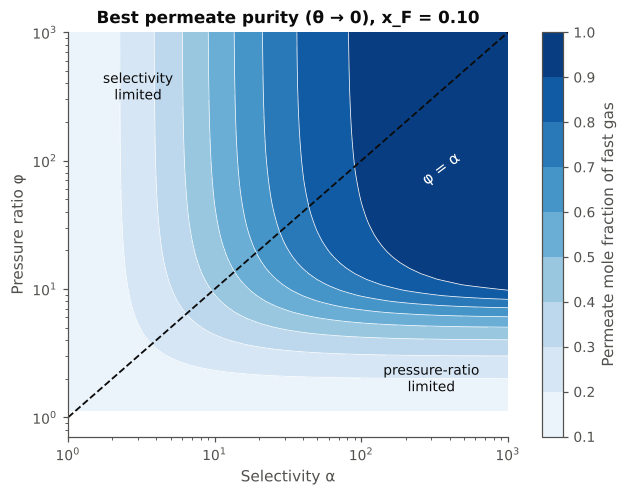

In [4]:
# Regime map: best possible permeate purity (theta -> 0) for a lean feed, x_F = 0.1
alphas = np.logspace(0, 3, 70); phis = np.logspace(0.05, 3, 70)
Z = np.array([[binary_limits(a, p, 0.1)["y_local"] for a in alphas] for p in phis])
fig, ax = plt.subplots(figsize=(5.6, 4.4), constrained_layout=True)
cs = ax.contourf(alphas, phis, Z, levels=np.linspace(0.1, 1, 10), cmap="Blues")
ax.contour(alphas, phis, Z, levels=np.linspace(0.1, 1, 10), colors="white", linewidths=0.5)
ax.plot(alphas, alphas, color="#0b0b0b", lw=1.2, ls="--")
ax.text(250, 120, "φ = α", color="white", rotation=37, ha="left", va="top")
ax.text(300, 1.6, "pressure-ratio\nlimited", color="#0b0b0b", ha="center", fontsize=9)
ax.text(3, 300, "selectivity\nlimited", color="#0b0b0b", ha="center", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(False)
ax.set_xlabel("Selectivity α"); ax.set_ylabel("Pressure ratio φ")
ax.set_title("Best permeate purity (θ → 0), x_F = 0.10")
fig.colorbar(cs, ax=ax, label="Permeate mole fraction of fast gas");

Read the contours. Where α > φ (bottom right) they run **horizontally**: a more selective
membrane does not help, only a higher pressure ratio does. Where φ > α (top left) they run
**vertically**: now selectivity is what counts. Good designs sit near the bend, φ ≈ α.